# Исследование обнаружения ошибок в обучающей выблрке(этапы1-7)

## Импорты и настройки

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    average_precision_score, roc_auc_score, accuracy_score,
    precision_recall_curve,
)
from cleanlab.rank import get_label_quality_scores

# Импорты из src
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src").is_dir():
    raise FileNotFoundError("Не найдена src")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import SimpleCNN, FashionCNN, count_trainable_parameters
from src.data import load_small_dataset
from src.training import train_one_epoch, predict, measure_cnn_quality, train_and_measure
from src.utils import set_seed, get_device

#константы
SEED = 42
DATASET_NAME = "FashionMNIST"  # MNIST или FashionMNIST
TRAIN_LIMIT = 50000
TEST_LIMIT = None
NOISE_TYPE = "symmetric" #"symmetric"  #"class_dependent", "instance_dependent"
NOISE_RATE = 0.20       #доля меток, которые испортим
FOLDS = 3              #для кросс-валидации
ENSEMBLE_SIZE = 3
EPOCHS = 50
OOF_EPOCHS = 50
BATCH_SIZE = 128
K_NEIGHBORS = 10
CNN_QUALITY_EPOCHS = 100
CNN_QUALITY_SEEDS = [SEED]
CLEANING_REPEAT_SEEDS = [SEED]
CLEANING_FINAL_EPOCHS = 50

# Переключатели oof методов(false, поскольку сейчас фокус на энтропию) 
RUN_LEGACY_OOF = True              # этапы 3-7 и сравнение с OOF/Cleanlab/3 сигналами
RUN_LEGACY_CLEANING = True         # этапы 7 и 9; требуют OOF-результатов
RUN_CLASSIFIER_COMPARISONS = True  # этап 1.1 и этап 10
RUN_CIFAR10N = True                # старый OOF-эксперимент на CIFAR-10N
RUN_SEI_CIFAR10N = True            # отдельная проверка SEI на CIFAR-10N (без OOF)

REQUIRE_CUDA = True
DEVICE = get_device(require_cuda=REQUIRE_CUDA)
if DEVICE.type == "cuda":
    print("Устройство:", torch.cuda.get_device_name(0))
    print("Версия CUDA в PyTorch:", torch.version.cuda)
else:
    print("Устройство:", DEVICE)

DATA_ROOT = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "results_vkr"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

set_seed()

Устройство: NVIDIA GeForce RTX 3060 Laptop GPU
Версия CUDA в PyTorch: 13.2


c:\Users\aptem\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## =============== **Этап 1** ===============


In [2]:
X_train, y_true, X_test, y_test = load_small_dataset(
    DATASET_NAME, TRAIN_LIMIT, TEST_LIMIT, data_root=DATA_ROOT, seed=SEED
)
NUM_CLASSES = 10
print("Датасет:", DATASET_NAME)
print("Размер обучающей выборки:", len(y_true))
print("Размер тестовой выборки:", len(y_test))


Датасет: FashionMNIST
Размер обучающей выборки: 50000
Размер тестовой выборки: 10000


## Этап 1.1. Оценка качества базовой CNN

Сравнивается качество одной и той же модели на 3000 и 10000 обучающих изображениях. Для оценки используется полный тестовый набор


Обучающая выборка: 10000, seed: 42
Эпоха 25/100
Эпоха 50/100
Эпоха 75/100
Эпоха 100/100

Обучающая выборка: 50000, seed: 42
Эпоха 25/100
Эпоха 50/100
Эпоха 75/100
Эпоха 100/100
Качество CNN на тестовой выборке (seed=42):


,Train samples,seed,Accuracy,Balanced accuracy,Macro-F1
0,10000,42,0.8765,0.8765,0.8748
1,50000,42,0.9024,0.9024,0.9024


,Train samples,Accuracy
0,10000,0.8765
1,50000,0.9024


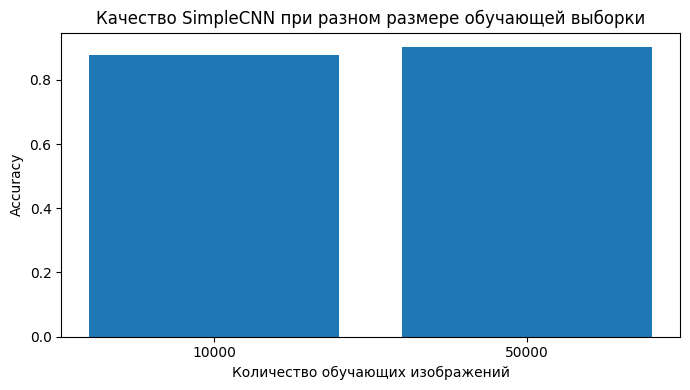

In [3]:
if RUN_CLASSIFIER_COMPARISONS:
    quality_rows = []
    quality_sizes = sorted(set([min(10000, len(y_true)), len(y_true)]))

    for sample_count in quality_sizes:
        for quality_seed in CNN_QUALITY_SEEDS:
            print(f"\nОбучающая выборка: {sample_count}, seed: {quality_seed}")
            metrics = measure_cnn_quality(
                X_train[:sample_count], y_true[:sample_count], X_test, y_test,
                epochs=CNN_QUALITY_EPOCHS, seed=quality_seed,
                num_classes=NUM_CLASSES, batch_size=BATCH_SIZE, device=DEVICE
            )
            quality_rows.append({"Train samples": sample_count, "seed": quality_seed, **metrics})

    cnn_quality_runs = pd.DataFrame(quality_rows)
    cnn_quality_summary = cnn_quality_runs[["Train samples", "Accuracy"]].copy()

    print("Качество CNN на тестовой выборке (seed=42):")
    display(cnn_quality_runs.round(4))

    display(cnn_quality_summary.round(4))

    cnn_quality_runs.to_csv(os.path.join(OUTPUT_DIR, "cnn_quality_runs.csv"), index=False)
    cnn_quality_summary.to_csv(os.path.join(OUTPUT_DIR, "cnn_quality_summary.csv"), index=False)

    plt.figure(figsize=(7, 4))
    plt.bar(cnn_quality_runs["Train samples"].astype(str), cnn_quality_runs["Accuracy"])
    plt.xlabel("Количество обучающих изображений")
    plt.ylabel("Accuracy")
    plt.title("Качество SimpleCNN при разном размере обучающей выборки")
    plt.tight_layout()
    plt.show()
else:
    print("Базовое сравнение классификаторов пропущено: RUN_CLASSIFIER_COMPARISONS=False")


## ===== **Этап 2. Генерация искусственного шума** =====

In [4]:
#ИСКУССТВЕННЫЙ ШУМ
def make_noisy_labels(X, y, noise_type, noise_rate, seed=SEED):
    """Меняет заданную долю меток и возвращает их плюс маску ошибок."""
    rng = np.random.default_rng(seed)
    y_original = y.cpu().numpy().copy()
    y_noisy = y_original.copy()
    n_classes = len(np.unique(y_original))
    n_errors = int(round(len(y_original) * noise_rate))

    if noise_type == "instance_dependent":
        variation = X.flatten(1).std(dim=1).cpu().numpy()
        weights = 1.0 / (variation + 0.05)
        weights = weights / weights.sum()
        bad_ids = rng.choice(len(y_original), size=n_errors, replace=False, p=weights)
    else:
        bad_ids = rng.choice(len(y_original), size=n_errors, replace=False)

    if noise_type == "class_dependent":
        y_noisy[bad_ids] = (y_original[bad_ids] + 1) % n_classes

    elif noise_type in ("symmetric", "instance_dependent"):
        new_labels = rng.integers(0, n_classes, size=n_errors)
        same = new_labels == y_original[bad_ids]
        while same.any():
            new_labels[same] = rng.integers(0, n_classes, size=same.sum())
            same = new_labels == y_original[bad_ids]
        y_noisy[bad_ids] = new_labels

    else:
        raise ValueError("Неизвестный тип шума")

    noise_mask = y_noisy != y_original
    return torch.tensor(y_noisy, dtype=torch.long), noise_mask


y_noisy, noise_mask = make_noisy_labels(X_train, y_true, NOISE_TYPE, NOISE_RATE)
print("Тип шума:", NOISE_TYPE)
print("Заданный уровень шума:", NOISE_RATE)
print("Фактически испорчено меток:", int(noise_mask.sum()), "из", len(noise_mask))

Тип шума: symmetric
Заданный уровень шума: 0.2
Фактически испорчено меток: 10000 из 50000


## **Этап 3: Базовые методы и out-of-fold предсказания**

Для каждого объекта модель формирует прогноз в фолде, где этот объект не участвовал в обучении, по этим прогнозам рассчитываются сигналы динамики, KNN и ансамбля, а также сравнительные оценки Cleanlab и small-loss

Для каждого обучающего объекта формируются три сигнала подозрительности

In [5]:
def get_oof_signals(X, y_observed, num_classes=10, folds=3,
                    ensemble_size=2, epochs=OOF_EPOCHS, seed=SEED):
    """Создаёт out-of-fold вероятности и три сигнала подозрительности

    X - изображения
    y_observed - имеющиеся метки, в том числе потенциально ошибочные

    """
    labels = y_observed.cpu().numpy()
    n = len(labels)
    in_channels = X.shape[1] # если форма х [3000, 1, 28, 28]

    oof_probs = np.zeros((n, num_classes)) #матрица  n * num_classes
    dynamic_score = np.zeros(n)
    knn_score = np.zeros(n)
    member_predictions = np.zeros((n, ensemble_size), dtype=int)

    splitter = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed) #обучающая выборка разделяется на 3 части

    for fold, (train_ids, valid_ids) in enumerate(splitter.split(np.zeros(n), labels)):
        print(f"Фолд {fold + 1}/{folds}")
        fold_probs = []     #вероятности классов
        fold_dynamic = []  #оценки динамики обучения
        fold_knn = []       #оценки несогласия ближайших соседей
        fold_predictions = [] #предсказанные классы моделей ансамбля


        for member in range(ensemble_size):
            #обучение моделей в каждом фолде
            set_seed(seed + fold * 100 + member)
            model = SimpleCNN(in_channels=in_channels, num_classes=num_classes).to(DEVICE)
            optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #оптимизатор адам будет обновлять обучаемые параметры CNN для уменьшения функции потерь

            #oбъединяет изображения и соответствующие метки в пары
            train_dataset = TensorDataset(X[train_ids], y_observed[train_ids])
            loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                                pin_memory=(DEVICE.type == "cuda"))
            history = []


            for epoch in range(epochs):
                train_one_epoch(model, loader, optimizer)
                epoch_probs, _ = predict(model, X[valid_ids])
                history.append(epoch_probs)

            #Получение вероятностей и признаков после обучения
            valid_probs, valid_features = predict(model, X[valid_ids])
            _, train_features = predict(model, X[train_ids])
            fold_probs.append(valid_probs)
            fold_predictions.append(valid_probs.argmax(axis=1)) #возвращает индекс класса с максимальной вероятностью для каждого объекта


            # 1/3 сигналов
            # Если модель регулярно даёт низкую вероятность записанной метке, score растёт
            history = np.stack(history, axis=0) #history был списком массивов вероятностей - тепрь один трёхмерный массив, например (2, 1000, 10) = [эпоха, объект, класс]

            #берет все эпохи, создаёт индексы проверочных объектов: 0, 1, .. len(valid_ids)-1 и возвращает записанные метки проверочных объектов
            observed_probs = history[:, np.arange(len(valid_ids)), labels[valid_ids]]

            #расчитывается подозрительность
            fold_dynamic.append(1.0 - observed_probs.mean(axis=0))

            #2 сигнал
            # KNN сравнивает метку объекта с метками ближайших обучающих объектов
            k = min(K_NEIGHBORS, len(train_ids)) #число соседей
            knn = NearestNeighbors(n_neighbors=k)
            knn.fit(train_features)

            neighbor_ids = knn.kneighbors(valid_features, return_distance=False)
            neighbor_labels = labels[train_ids][neighbor_ids]

            #Сравнить метки соседей с меткой проверочного объекта
            disagreement = (neighbor_labels != labels[valid_ids, None]).mean(axis=1)
            fold_knn.append(disagreement)

        oof_probs[valid_ids] = np.mean(fold_probs, axis=0)
        dynamic_score[valid_ids] = np.mean(fold_dynamic, axis=0)
        knn_score[valid_ids] = np.mean(fold_knn, axis=0)
        member_predictions[valid_ids] = np.stack(fold_predictions, axis=1)

    # Голосование моделей: сигнал высокий, если большинство моделей отвергает записанную метку
    ensemble_score = np.zeros(n)
    for i in range(n):
        votes = np.bincount(member_predictions[i], minlength=num_classes) #количество голосов за каждый класс
        majority_class = votes.argmax()
        agreement = votes.max() / ensemble_size #0.33, 0.67 или 1
        if majority_class != labels[i]:
            ensemble_score[i] = agreement
        #Если большинство моделей выбирает не тот класс, который записан в датасете -  объект получает ненулевой сигнал подозрительности, чем больше согласие моделей в пользу альтернативного класса, тем выше оценка


    return oof_probs, dynamic_score, knn_score, ensemble_score


def normalize_score(score):
    score = np.asarray(score, dtype=float)
    low, high = score.min(), score.max()
    if high == low:
        return np.zeros_like(score)
    return (score - low) / (high - low)


def make_score_methods(y_observed, oof_probs, dynamic_score, knn_score, ensemble_score):
    """Считает Cleanlab, small-loss, отдельные сигналы, их комбинацию и абляции"""
    labels = y_observed.cpu().numpy() if torch.is_tensor(y_observed) else np.asarray(y_observed)

    label_quality = get_label_quality_scores(labels=labels, pred_probs=oof_probs)
    cleanlab_score = 1.0 - label_quality #высокое значение =  метка выглядит более подозрительной

    observed_probs = oof_probs[np.arange(len(labels)), labels]
    small_loss_score = -np.log(np.clip(observed_probs, 1e-8, 1.0))

    D = normalize_score(dynamic_score)
    K = normalize_score(knn_score)
    E = normalize_score(ensemble_score)
    combined_score = (D + K + E) / 3.0


    methods = {
        "Cleanlab": cleanlab_score,
        "Small-loss (OOF)": small_loss_score,
        "KNN": knn_score,          #Насколько метка объекта отличается от меток похожих объектов

        "Ensemble agreement": ensemble_score, #Насколько предсказания моделей ансамбля не согласуются с записанной меткой

        "Dynamics": dynamic_score, #Насколько уверенно модель предсказывает записанную метку в течение обучения

        "Combined (D+K+E)": combined_score,
        "Ablation: without D": (K + E) / 2.0,
        "Ablation: without K": (D + E) / 2.0,
        "Ablation: without E": (D + K) / 2.0,
    }
    return methods, combined_score


""" bad_mask это массив, в котором мы знаем, какие метки действительно испортили при создании шума"""
def evaluate_score(name, score, bad_mask):
    bad_mask = np.asarray(bad_mask).astype(int)
    score = np.asarray(score)
    k = max(1, int(bad_mask.sum()))  # K берётся из числа реальных ошибок только для оценки
    top_ids = np.argsort(score)[::-1][:k]
    return {
        "Метод": name,
        "Precision@K": bad_mask[top_ids].mean(), #Чем выше Precision@K, тем меньше правильных меток ошибочно отнесли к подозрительным при таком размере списка
        "Average Precision": average_precision_score(bad_mask, score), #Высокий AP = испорченные метки в целом оказываются ближе к началу списка подозрительности
        "ROC-AUC": roc_auc_score(bad_mask, score) if len(np.unique(bad_mask)) > 1 else np.nan,
        #способность рейтинга отделять испорченные метки от правильных при рассмотрении разных порогов
        }


if RUN_LEGACY_OOF:
    oof_probs, dynamic_score, knn_score, ensemble_score = get_oof_signals(
        X_train, y_noisy, num_classes=NUM_CLASSES,
        folds=FOLDS, ensemble_size=ENSEMBLE_SIZE, epochs=OOF_EPOCHS
    )
    score_methods, combined_score = make_score_methods(
        y_noisy, oof_probs, dynamic_score, knn_score, ensemble_score
    )
else:
    oof_probs = dynamic_score = knn_score = ensemble_score = None
    score_methods, combined_score = {}, None
    print("OOF и три сигнала отключены: RUN_LEGACY_OOF=False")

Фолд 1/3
Фолд 2/3
Фолд 3/3


60ая строка =  1 + Sloss


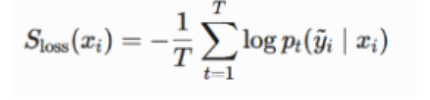

## **Этап 4 Сравнение обнаружения ошибок**

Precision@K, Average Precision и ROC-AUC рассчитываются с использованием маски искусственных ошибок только на этапе оценки. Таблица сортируется по Average Precision

Результаты обнаружения искусственно испорченных меток:


,Метод,Precision@K,Average Precision,ROC-AUC
0,Dynamics,0.9361,0.981379,0.994735
1,Ablation: without E,0.9409,0.980373,0.994869
2,Cleanlab,0.9434,0.978630,0.994884
3,Small-loss (OOF),0.9434,0.978630,0.994884
4,Combined (D+K+E),0.8988,0.973145,0.992843
5,Ablation: without K,0.8734,0.969291,0.991367
6,KNN,0.9172,0.944268,0.990497
7,Ablation: without D,0.8764,0.941294,0.988518
8,Ensemble agreement,0.8284,0.813575,0.967501


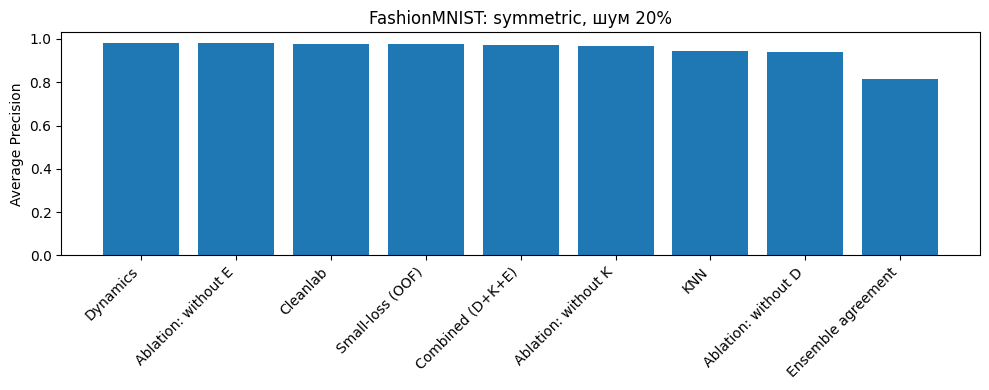

,index,true_label (только оценка),noisy_label,была искусственная ошибка,score
0,47217,4,0,1,1.000000
1,26061,4,0,1,0.999831
2,15829,5,3,1,0.999688
3,7012,5,9,1,0.999632
4,26942,8,1,1,0.999430
5,40791,8,3,1,0.999409
6,26366,5,3,1,0.999367
7,30270,5,8,1,0.999349
8,10931,8,1,1,0.999347
9,9611,4,3,1,0.999304


In [6]:
if RUN_LEGACY_OOF:
    noise_mask_np = noise_mask.astype(int)  # только для оценки, модель эту маску не получает

    results = [evaluate_score(name, score, noise_mask_np) for name, score in score_methods.items()]
    results_df = pd.DataFrame(results).sort_values("Average Precision", ascending=False).reset_index(drop=True)
    print("Результаты обнаружения искусственно испорченных меток:")
    display(results_df)
    results_df.to_csv(os.path.join(OUTPUT_DIR, "results_detection_synthetic.csv"), index=False)

    plt.figure(figsize=(10, 4))
    plt.bar(results_df["Метод"], results_df["Average Precision"])
    plt.ylabel("Average Precision")
    plt.xticks(rotation=45, ha="right")
    plt.title(f"{DATASET_NAME}: {NOISE_TYPE}, шум {NOISE_RATE:.0%}")
    plt.tight_layout()
    plt.show()

    ranked_ids = np.argsort(combined_score)[::-1][:10]
    examples = pd.DataFrame({
        "index": ranked_ids,
        "true_label (только оценка)": y_true.numpy()[ranked_ids],
        "noisy_label": y_noisy.numpy()[ranked_ids],
        "была искусственная ошибка": noise_mask_np[ranked_ids],
        "score": combined_score[ranked_ids],
    })
    display(examples)
else:
    print("Этап 4 пропущен: RUN_LEGACY_OOF=False")


## Этап 5. Абляционные эксперименты

Сравнивается полная комбинация с вариантами, из которых убран один сигнал. Это позволяет оценить, добавляет ли каждый компонент полезную информацию.

In [7]:
if RUN_LEGACY_OOF:
    # ЭТАП 5: АБЛЯЦИОННЫЕ ЭКСПЕРИМЕНТЫ
    # без D убрана динамика обучения; без K убраны соседи; без E убрано голосование.
    combined_ap = results_df.loc[results_df["Метод"] == "Combined (D+K+E)", "Average Precision"].iloc[0]
    print("AP полного метода:", round(float(combined_ap), 4))
    for method_name in ["Ablation: without D", "Ablation: without K", "Ablation: without E"]:
        value = results_df.loc[results_df["Метод"] == method_name, "Average Precision"].iloc[0]
        print(method_name, "AP =", round(float(value), 4), "разница с полным методом =", round(float(combined_ap - value), 4))
else:
    print("Этап 5 пропущен: RUN_LEGACY_OOF=False")


AP полного метода: 0.9731
Ablation: without D AP = 0.9413 разница с полным методом = 0.0319
Ablation: without K AP = 0.9693 разница с полным методом = 0.0039
Ablation: without E AP = 0.9804 разница с полным методом = -0.0072


## Этап 6. Проверка на реальном шуме CIFAR-10N

 Для запуска нужен `CIFAR-10_human.pt`, он лежит в репозитории: https://github.com/UCSC-REAL/cifar-10-100n
Протокол использует человеческие метки как шумные, а `clean_label` из бенчмарка как опорный вариант для оценки.

In [8]:
#Настройки для 6 этапа
RUN_CIFAR10N = False
CIFAR10N_LABEL_TYPE = "aggre_label"  # aggre_label, random_label1/2/3, worse_label
CIFAR10N_TRAIN_LIMIT = TRAIN_LIMIT
CIFAR10N_TEST_LIMIT = 1000
CIFAR10N_FOLDS = 3
CIFAR10N_ENSEMBLE_SIZE = 2
CIFAR10N_EPOCHS = OOF_EPOCHS


#7 этап работает как на данных 1-5 этапов, так и на данных 6 этапа, эпохи можно увеличить

CLEANING_EPOCHS = 3
RUN_STAGE7_CLEANING = False
CLEANING_USE_CIFAR10N = False  # если true- будут использоваться данные этапа 6
CIFAR10N_FILE = os.environ.get("CIFAR10N_FILE", os.path.join(DATA_ROOT, "CIFAR-10_human.pt"))



In [9]:
# ЭТАП 6: РЕАЛЬНЫЕ МЕТКИ CIFAR-10N
def load_cifar10n_data(label_type="aggre_label", train_limit=3000, test_limit=1000, file_path=CIFAR10N_FILE):

    try:
        label_data = torch.load(file_path, map_location="cpu", weights_only=False)
    except TypeError:
        label_data = torch.load(file_path, map_location="cpu")

    if label_type not in label_data:
        raise ValueError(f"В файле нет ключа {label_type}. Доступно: {list(label_data.keys())}")
 
    datasets.CIFAR10.url = (
    "https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/"
    "resolve/c6e562aecc3a2dd5ee13f9d91630d81219c6a126/"
    "cifar-10-python.tar.gz"
    )

    cifar_train = datasets.CIFAR10(root=DATA_ROOT,
                                    train=True, download=True)
    cifar_test = datasets.CIFAR10(root=DATA_ROOT,
                                    train=False, download=True)

    clean_all = torch.as_tensor(label_data["clean_label"], dtype=torch.long)
    noisy_all = torch.as_tensor(label_data[label_type], dtype=torch.long)

    generator = torch.Generator().manual_seed(SEED)
    train_ids = torch.randperm(len(clean_all), generator=generator)[:train_limit]
    test_ids = torch.randperm(len(cifar_test.targets), generator=generator)[:test_limit]

    train_images = torch.as_tensor(cifar_train.data[train_ids.numpy()]).permute(0, 3, 1, 2).float() / 255.0
    test_images = torch.as_tensor(cifar_test.data[test_ids.numpy()]).permute(0, 3, 1, 2).float() / 255.0
    test_labels_all = torch.as_tensor(cifar_test.targets, dtype=torch.long)

    return {
        "X_train": train_images,
        "y_clean": clean_all[train_ids],
        "y_noisy": noisy_all[train_ids],
        "X_test": test_images,
        "y_test": test_labels_all[test_ids],
        "label_type": label_type,
    }


def run_cifar10n_experiment():
    data = load_cifar10n_data(
        label_type=CIFAR10N_LABEL_TYPE,
        train_limit=CIFAR10N_TRAIN_LIMIT,
        test_limit=CIFAR10N_TEST_LIMIT
    )

    real_oof_probs, real_dynamic, real_knn, real_ensemble = get_oof_signals(
        data["X_train"], data["y_noisy"], num_classes=10,
        folds=CIFAR10N_FOLDS, ensemble_size=CIFAR10N_ENSEMBLE_SIZE,
        epochs=CIFAR10N_EPOCHS, seed=SEED + 500
    )

    real_methods, real_combined = make_score_methods(
        data["y_noisy"], real_oof_probs, real_dynamic, real_knn, real_ensemble
    )

    real_noise_mask = (data["y_noisy"].numpy() != data["y_clean"].numpy()).astype(int)
    real_results = pd.DataFrame([
        evaluate_score(name, score, real_noise_mask)
        for name, score in real_methods.items()
    ]).sort_values("Average Precision", ascending=False).reset_index(drop=True)

    print("CIFAR-10N label set:", data["label_type"])
    print("Ошибка меток относительно оригинальных CIFAR-10 labels в подвыборке:", f"{real_noise_mask.mean():.2%}")
    display(real_results)

    real_results.to_csv(os.path.join(OUTPUT_DIR, "results_detection_cifar10n.csv"), index=False)
    
    data["oof_probs"] = real_oof_probs
    data["score_methods"] = real_methods
    data["combined_score"] = real_combined
    data["noise_mask"] = real_noise_mask
    data["results_df"] = real_results

    return data


cifar_result = None

if RUN_CIFAR10N and RUN_LEGACY_OOF:
    cifar_result = run_cifar10n_experiment()
else:
    cifar_result = None
    print("Старый CIFAR-10N/OOF эксперимент пропущен")


Старый CIFAR-10N/OOF эксперимент пропущен


## Этап 7. Проверка пользы очистки

С нуля обучается один классификатор на исходных шумных метках, один после исправления top-K по собственному рейтингу, один после исправления по Cleanlab и один после удаления top-K подозрительных примеров

В основном запуске этот короткий эксперимент отключён, итоговое сравнение проводится на этапе 9

In [10]:
# ЭТАП 7: ПЕРЕОБУЧЕНИЕ ПОСЛЕ ОЧИСТКИ
def repair_labels(y_noisy_local, score, oof_probs_local, fraction):
    y_fixed = y_noisy_local.cpu().numpy().copy()
    count = max(1, int(round(len(y_fixed) * fraction)))

    suspicious_ids = np.argsort(score)[::-1][:count]
    predicted_labels = oof_probs_local.argmax(axis=1)
    
    y_fixed[suspicious_ids] = predicted_labels[suspicious_ids]
    
    return torch.tensor(y_fixed, dtype=torch.long), suspicious_ids


def remove_suspicious(X, y_noisy_local, score, fraction):
    count = max(1, int(round(len(y_noisy_local) * fraction)))

    suspicious_ids = np.argsort(score)[::-1][:count]
  
    keep_mask = np.ones(len(y_noisy_local), dtype=bool)
    keep_mask[suspicious_ids] = False
    
    return X[keep_mask], y_noisy_local[keep_mask], suspicious_ids


def run_cleaning_experiment(X_train_local, y_noisy_local, X_test_local, y_test_local,
                            oof_probs_local, methods_local, top_fraction, epochs=3):

    num_classes = int(max(y_noisy_local.max().item(), y_test_local.max().item()) + 1)
    rows = []

    accuracy = train_and_measure(X_train_local, y_noisy_local, X_test_local, y_test_local,
                                 num_classes, epochs, SEED + 1000)
    rows.append({"Вариант": "Исходные шумные метки", "Test accuracy": accuracy,
                 "Исправлено/удалено объектов": 0})

    # Исправление собственным комбинированным рейтингом
    fixed_y, fixed_ids = repair_labels(
        y_noisy_local, methods_local["Combined (D+K+E)"], oof_probs_local, top_fraction
    )

    accuracy = train_and_measure(X_train_local, fixed_y, X_test_local, y_test_local,
                                 num_classes, epochs, SEED + 1001)
    
    rows.append({"Вариант": "Combined: исправление", "Test accuracy": accuracy,
                 "Исправлено/удалено объектов": len(fixed_ids)})

    # Исправление той же доли объектов по ранжированию Cleanlab
    fixed_cleanlab_y, cleanlab_ids = repair_labels(
        y_noisy_local, methods_local["Cleanlab"], oof_probs_local, top_fraction
    
    )
    accuracy = train_and_measure(X_train_local, fixed_cleanlab_y, X_test_local, y_test_local,
                                 num_classes, epochs, SEED + 1002)
    
    rows.append({"Вариант": "Cleanlab: исправление", "Test accuracy": accuracy,
                 "Исправлено/удалено объектов": len(cleanlab_ids)})

    # Удаление объектов, выбранных собственным рейтингом
    X_kept, y_kept, removed_ids = remove_suspicious(
        X_train_local, y_noisy_local, methods_local["Combined (D+K+E)"], top_fraction
    )
    
    accuracy = train_and_measure(X_kept, y_kept, X_test_local, y_test_local,
                                 num_classes, epochs, SEED + 1003)
    
    rows.append({"Вариант": "Combined: удаление", "Test accuracy": accuracy,
                 "Исправлено/удалено объектов": len(removed_ids)})

    cleaning_results = pd.DataFrame(rows).sort_values("Test accuracy", ascending=False).reset_index(drop=True)
    return cleaning_results



if RUN_STAGE7_CLEANING and RUN_LEGACY_OOF:
    if CLEANING_USE_CIFAR10N:
        if cifar_result is None:
            raise RuntimeError("Сначала установите RUN_CIFAR10N = True и выполните этап 6.")
        
        clean_X_train = cifar_result["X_train"]
        clean_X_test = cifar_result["X_test"]
        
        clean_y_noisy = cifar_result["y_noisy"]
        clean_y_test = cifar_result["y_test"]
        
        clean_oof_probs = cifar_result["oof_probs"]
        clean_methods = cifar_result["score_methods"]

        # Приближённые опубликованные уровни шума CIFAR-10N; это настройка K, не метки объектов

        CIFAR10N_RATES = {
            "aggre_label": 0.0903,
            "random_label1": 0.1723,
            "random_label2": 0.1812,
            "random_label3": 0.1764,
            "worse_label": 0.4021,
        }

        clean_fraction = CIFAR10N_RATES.get(CIFAR10N_LABEL_TYPE, 0.18)
        cleaning_title = "CIFAR-10N"

    else:
        clean_X_train = X_train
        clean_X_test = X_test

        clean_y_noisy = y_noisy
        clean_y_test = y_test
        
        clean_oof_probs = oof_probs
        clean_methods = score_methods
        
        clean_fraction = NOISE_RATE
        cleaning_title = DATASET_NAME + " (synthetic noise)"

    print("Этап 7:", cleaning_title)
    print("Доля объектов, выбранных для очистки:", f"{clean_fraction:.1%}")

    cleaning_results = run_cleaning_experiment(
        clean_X_train, clean_y_noisy, clean_X_test, clean_y_test,
        clean_oof_probs, clean_methods, top_fraction=clean_fraction,
        epochs=CLEANING_EPOCHS
    )

    display(cleaning_results)
    cleaning_results.to_csv(os.path.join(OUTPUT_DIR, "results_cleaning.csv"), index=False)

    plt.figure(figsize=(8, 4))
    plt.bar(cleaning_results["Вариант"], cleaning_results["Test accuracy"])
    plt.ylabel("Test accuracy")
    plt.xticks(rotation=25, ha="right")
    plt.title("Качество классификатора после очистки: " + cleaning_title)
    plt.tight_layout()
    plt.show()

    print("CSV сохранены:", os.path.join(OUTPUT_DIR, "results_detection_synthetic.csv"), "и", os.path.join(OUTPUT_DIR, "results_cleaning.csv"))
    if cifar_result is not None:
        print("CSV CIFAR-10N:", os.path.join(OUTPUT_DIR, "results_detection_cifar10n.csv"))

## Этап 9. Повторная проверка очистки после увеличения выборки и числа эпох

Используются три запуска из этапа 8.4. Повторное обучение OOF-моделей не проводится, чтобы не тратить время на одинаковые вычисления

нужен для того, чтобы узнать, действительно
ли методы обнаружения ошибок помогают улучшить качество классификатора после очистки данных

In [11]:
CLEANING_FINAL_EPOCHS = 50
def run_cleaning_experiment_final(X_train_local, y_noisy_local, X_test_local, y_test_local,
                                  y_clean_local, oof_probs_local, methods_local,
                                  top_fraction, epochs=50, seed=SEED):
    num_classes_local = int(max(y_noisy_local.max().item(), y_test_local.max().item()) + 1)
# Для вариантов одного запуска используется одинаковая инициализация CNN
    classifier_seed = 10000 + seed
    rows = []

    accuracy = train_and_measure(
        X_train_local, y_noisy_local, X_test_local, y_test_local,
        num_classes_local, epochs, classifier_seed
    )
    rows.append({"Вариант": "Исходные шумные метки", "Test accuracy": accuracy,
                 "Выбрано подозрительных объектов": 0, "Размер train": len(y_noisy_local)})

    fixed_y, fixed_ids = repair_labels(
        y_noisy_local, methods_local["Combined (D+K+E)"], oof_probs_local, top_fraction
    )
    accuracy = train_and_measure(
        X_train_local, fixed_y, X_test_local, y_test_local,
        num_classes_local, epochs, classifier_seed
    )
    rows.append({"Вариант": "Combined: исправление", "Test accuracy": accuracy,
                 "Выбрано подозрительных объектов": len(fixed_ids), "Размер train": len(fixed_y)})

    fixed_cleanlab_y, cleanlab_ids = repair_labels(
        y_noisy_local, methods_local["Cleanlab"], oof_probs_local, top_fraction
    )
    
    accuracy = train_and_measure(
        X_train_local, fixed_cleanlab_y, X_test_local, y_test_local,
        num_classes_local, epochs, classifier_seed
    )
    rows.append({"Вариант": "Cleanlab: исправление", "Test accuracy": accuracy,
                 "Выбрано подозрительных объектов": len(cleanlab_ids), "Размер train": len(fixed_cleanlab_y)})

    X_kept, y_kept, combined_removed_ids = remove_suspicious(
        X_train_local, y_noisy_local, methods_local["Combined (D+K+E)"], top_fraction
    )
    accuracy = train_and_measure(
        X_kept, y_kept, X_test_local, y_test_local,
        num_classes_local, epochs, classifier_seed
    )
    rows.append({"Вариант": "Combined: удаление", "Test accuracy": accuracy,
                 "Выбрано подозрительных объектов": len(combined_removed_ids), "Размер train": len(y_kept)})

    X_kept_cleanlab, y_kept_cleanlab, cleanlab_removed_ids = remove_suspicious(
        X_train_local, y_noisy_local, methods_local["Cleanlab"], top_fraction
    )
    accuracy = train_and_measure(
        X_kept_cleanlab, y_kept_cleanlab, X_test_local, y_test_local,
        num_classes_local, epochs, classifier_seed
    )
    rows.append({"Вариант": "Cleanlab: удаление", "Test accuracy": accuracy,
                 "Выбрано подозрительных объектов": len(cleanlab_removed_ids),
                 "Размер train": len(y_kept_cleanlab)})

    accuracy = train_and_measure(
        X_train_local, y_clean_local, X_test_local, y_test_local,
        num_classes_local, epochs, classifier_seed
    )
    rows.append({"Вариант": "Чистые метки (эталон)", "Test accuracy": accuracy,
                 "Выбрано подозрительных объектов": 0, "Размер train": len(y_clean_local)})

    return pd.DataFrame(rows)


if RUN_LEGACY_CLEANING and RUN_LEGACY_OOF:
    # Для очистки используются те же запуски, что и при сравнении методов обнаружения
    cleaning_repeat_rows = []
    for cleaning_seed in CLEANING_REPEAT_SEEDS:
        print(f"\nОчистка, seed={cleaning_seed}")
        cached = replicate_cache[cleaning_seed]
        y_noisy_repeat = cached["y_noisy"]
        oof_repeat = cached["oof_probs"]
        methods_repeat = cached["methods"]

        run_result = run_cleaning_experiment_final(
            X_train, y_noisy_repeat, X_test, y_test, y_true,
            oof_repeat, methods_repeat, top_fraction=NOISE_RATE,
            epochs=CLEANING_FINAL_EPOCHS, seed=cleaning_seed
        )
        run_result["seed"] = cleaning_seed
        run_result["noise_type"] = NOISE_TYPE
        run_result["noise_rate"] = NOISE_RATE
        run_result["OOF epochs"] = OOF_EPOCHS
        # run_result["SEI epochs"] = SEI_EPOCHS
        run_result["CNN epochs"] = CLEANING_FINAL_EPOCHS
        cleaning_repeat_rows.append(run_result)

    cleaning_runs = pd.concat(cleaning_repeat_rows, ignore_index=True)
    cleaning_summary = cleaning_runs[[
        "Вариант", "Test accuracy", "Выбрано подозрительных объектов", "Размер train"
    ]].copy()

    print("Результаты очистки для seed=42:")
    display(cleaning_runs.sort_values("Test accuracy", ascending=False).round(4))
    display(cleaning_summary.round(4))

    cleaning_runs.to_csv(os.path.join(OUTPUT_DIR, "results_cleaning_repeats.csv"), index=False)
    cleaning_summary.to_csv(os.path.join(OUTPUT_DIR, "results_cleaning_summary.csv"), index=False)

    plot_data = cleaning_summary.sort_values("Test accuracy", ascending=False)
    plt.figure(figsize=(10, 5))
    plt.bar(plot_data["Вариант"], plot_data["Test accuracy"])
    plt.ylabel("Test accuracy")
    plt.xticks(rotation=25, ha="right")
    plt.title("Качество SimpleCNN после очистки (seed=42)")
    plt.tight_layout()
    plt.show()
else:
    print("Этап 9 (очистка через OOF/Combined/Cleanlab) пропущен")



Очистка, seed=42


NameError: name 'replicate_cache' is not defined

## Этап 10. Проверка альтернативной FashionCNN(модель Елизаветы) на тех же результатах

In [ ]:
if RUN_CLASSIFIER_COMPARISONS and RUN_LEGACY_OOF:
    # Считаем параметры обеих архитектур для понимания их размера
    print("Параметров SimpleCNN:", count_trainable_parameters(SimpleCNN()))
    print("Параметров FashionCNN:", count_trainable_parameters(FashionCNN()))


    def train_fashioncnn_and_measure(
        X_fit_raw,
        y_fit,
        X_eval_raw,
        y_eval,
        epochs,
        seed,
        verbose=False,
    ):
        """Обучает FashionCNN и считает метрики на тестовой выборке."""
        set_seed(seed)

        # Статистики считаются только по тем изображениям, на которых обучается модель
        mean = X_fit_raw.mean()
        std = X_fit_raw.std(unbiased=False)
        if std.item() <= 0:
            raise ValueError("Стандартное отклонение обучающей выборки должно быть больше нуля")

        X_fit = (X_fit_raw - mean) / std
        X_eval = (X_eval_raw - mean) / std

        model = FashionCNN(dropout=0.3).to(DEVICE)
        loader = DataLoader(
            TensorDataset(X_fit, y_fit),
            batch_size=BATCH_SIZE,
            shuffle=True,
            pin_memory=(DEVICE.type == "cuda"),
        )
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

        for epoch in range(1, epochs + 1):
            train_one_epoch(model, loader, optimizer)
            if verbose and (epoch % 25 == 0 or epoch == epochs):
                print(f"Эпоха {epoch}/{epochs}")

        probabilities, _ = predict(model, X_eval)
        predictions = probabilities.argmax(axis=1)
        targets = y_eval.cpu().numpy()

        return {"Accuracy": accuracy_score(targets, predictions)}


    # 10.1. Базовое качество FashionCNN
    fashion_quality_rows = []
    fashion_quality_sizes = sorted(set([min(10000, len(y_true)), len(y_true)]))

    for sample_count in fashion_quality_sizes:
        for quality_seed in CNN_QUALITY_SEEDS:
            print(f"\nFashionCNN, обучающая выборка: {sample_count}, seed: {quality_seed}")
            metrics = train_fashioncnn_and_measure(
                X_train[:sample_count],
                y_true[:sample_count],
                X_test,
                y_test,
                epochs=CNN_QUALITY_EPOCHS,
                seed=quality_seed,
                verbose=True,
            )
            fashion_quality_rows.append({
                "Train samples": sample_count,
                "seed": quality_seed,
                **metrics,
            })

    fashion_cnn_quality_runs = pd.DataFrame(fashion_quality_rows)
    fashion_cnn_quality_summary = (
        fashion_cnn_quality_runs.groupby("Train samples", as_index=False)["Accuracy"]
        .mean()
    )

    print("Качество FashionCNN:")
    display(fashion_cnn_quality_runs.round(4))
    print("Accuracy для seed=42:")
    display(fashion_cnn_quality_summary.round(4))

    fashion_cnn_quality_runs.to_csv(
        os.path.join(OUTPUT_DIR, "fashion_cnn_quality_runs.csv"), index=False
    )
    fashion_cnn_quality_summary.to_csv(
        os.path.join(OUTPUT_DIR, "fashion_cnn_quality_summary.csv"), index=False
    )

    # Сравнение исходной SimpleCNN и новой FashionCNN на одинаковых размерах выборки и seed
    simple_quality = cnn_quality_runs.copy()
    simple_quality["Model"] = "SimpleCNN"
    fashion_quality = fashion_cnn_quality_runs.copy()
    fashion_quality["Model"] = "FashionCNN"
    architecture_quality_comparison = pd.concat(
        [simple_quality, fashion_quality], ignore_index=True
    )

    architecture_quality_summary = (
        architecture_quality_comparison.groupby(
            ["Model", "Train samples"], as_index=False
        )["Accuracy"].mean()
    )

    print("Сравнение базового качества двух архитектур:")
    display(architecture_quality_summary.round(4))
    architecture_quality_comparison.to_csv(
        os.path.join(OUTPUT_DIR, "architecture_quality_comparison.csv"), index=False
    )
    architecture_quality_summary.to_csv(
        os.path.join(OUTPUT_DIR, "architecture_quality_summary.csv"), index=False
    )


    # 10.2. Проверка тех же способов очистки с итоговым классификатором FashionCNN
    if "replicate_cache" not in globals() or not replicate_cache:
        raise RuntimeError("Сначала выполни этап 8.4: в replicate_cache должны быть результаты этапа 8.4 для seed=42")

    fashion_cleaning_rows = []

    for cleaning_seed in sorted(replicate_cache):
        cached = replicate_cache[cleaning_seed]
        y_noisy_repeat = cached["y_noisy"]
        oof_repeat = cached["oof_probs"]
        methods_repeat = cached["methods"]

        fixed_combined, combined_fixed_ids = repair_labels(
            y_noisy_repeat,
            methods_repeat["Combined (D+K+E)"],
            oof_repeat,
            NOISE_RATE,
        )
        fixed_cleanlab, cleanlab_fixed_ids = repair_labels(
            y_noisy_repeat,
            methods_repeat["Cleanlab"],
            oof_repeat,
            NOISE_RATE,
        )
        X_combined_kept, y_combined_kept, combined_removed_ids = remove_suspicious(
            X_train, y_noisy_repeat, methods_repeat["Combined (D+K+E)"], NOISE_RATE
        )
        X_cleanlab_kept, y_cleanlab_kept, cleanlab_removed_ids = remove_suspicious(
            X_train, y_noisy_repeat, methods_repeat["Cleanlab"], NOISE_RATE
        )

        variants = [
            ("Исходные шумные метки", X_train, y_noisy_repeat, 0),
            ("Combined: исправление", X_train, fixed_combined, len(combined_fixed_ids)),
            ("Cleanlab: исправление", X_train, fixed_cleanlab, len(cleanlab_fixed_ids)),
            ("Combined: удаление", X_combined_kept, y_combined_kept, len(combined_removed_ids)),
            ("Cleanlab: удаление", X_cleanlab_kept, y_cleanlab_kept, len(cleanlab_removed_ids)),
            ("Чистые метки (эталон)", X_train, y_true, 0),
        ]

        # Одинаковая инициализация для всех шести вариантов внутри одного seed
        classifier_seed = 10000 + cleaning_seed

        for variant_name, X_variant, y_variant, changed_count in variants:
            print(f"FashionCNN | seed={cleaning_seed} | {variant_name}")
            metrics = train_fashioncnn_and_measure(
                X_variant,
                y_variant,
                X_test,
                y_test,
                epochs=CLEANING_FINAL_EPOCHS,
                seed=classifier_seed,
                verbose=False,
            )
            fashion_cleaning_rows.append({
                "Вариант": variant_name,
                **metrics,
                "Выбрано подозрительных объектов": changed_count,
                "Размер train": len(y_variant),
                "seed": cleaning_seed,
                "noise_type": NOISE_TYPE,
                "noise_rate": NOISE_RATE,
                "CNN epochs": CLEANING_FINAL_EPOCHS,
            })

    fashion_cleaning_runs = pd.DataFrame(fashion_cleaning_rows)
    fashion_cleaning_summary = (
        fashion_cleaning_runs.groupby("Вариант", as_index=False)["Accuracy"]
        .mean()
    )

    print("Результаты FashionCNN после очистки:")
    display(fashion_cleaning_runs.sort_values(["Вариант", "seed"]).round(4))
    print("Сводка для seed=42:")
    display(fashion_cleaning_summary.round(4))

    fashion_cleaning_runs.to_csv(
        os.path.join(OUTPUT_DIR, "fashion_cnn_cleaning_runs.csv"), index=False
    )
    fashion_cleaning_summary.to_csv(
        os.path.join(OUTPUT_DIR, "fashion_cnn_cleaning_summary.csv"), index=False
    )

    # Сопоставляем accuracy с уже полученным результатом SimpleCNN
    simple_cleaning_comparison = cleaning_runs[["Вариант", "Test accuracy", "seed"]].copy()
    simple_cleaning_comparison = simple_cleaning_comparison.rename(
        columns={"Test accuracy": "Accuracy"}
    )
    simple_cleaning_comparison["Model"] = "SimpleCNN"

    fashion_cleaning_comparison = fashion_cleaning_runs[
        ["Вариант", "Accuracy", "seed"]
    ].copy()
    fashion_cleaning_comparison["Model"] = "FashionCNN"

    cleaning_architecture_comparison = pd.concat(
        [simple_cleaning_comparison, fashion_cleaning_comparison],
        ignore_index=True,
    )
    cleaning_architecture_summary = (
        cleaning_architecture_comparison.groupby(
            ["Model", "Вариант"], as_index=False
        )["Accuracy"].mean()
    )

    print("Сравнение очистки для SimpleCNN и FashionCNN:")
    display(cleaning_architecture_summary.round(4))
    cleaning_architecture_comparison.to_csv(
        os.path.join(OUTPUT_DIR, "cleaning_architecture_comparison.csv"), index=False
    )
    cleaning_architecture_summary.to_csv(
        os.path.join(OUTPUT_DIR, "cleaning_architecture_summary.csv"), index=False
    )

    plot_data = cleaning_architecture_summary.sort_values("Accuracy", ascending=False)
    plt.figure(figsize=(12, 5))
    for model_name, group in plot_data.groupby("Model"):
        plt.plot(group["Вариант"], group["Accuracy"], marker="o", label=model_name)
    plt.ylabel("Test accuracy")
    plt.xticks(rotation=25, ha="right")
    plt.title("Влияние очистки на качество двух архитектур")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("Результаты сохранены в:", OUTPUT_DIR)
else:
    print("Этап 10 / FashionCNN пропущен: RUN_CLASSIFIER_COMPARISONS=False")


Этап 10 / FashionCNN пропущен: RUN_CLASSIFIER_COMPARISONS=False
